In [87]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [88]:
df = pd.read_csv('/content/insurance.csv')

In [89]:
df

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.54830
1334,18,female,31.920,0,no,northeast,2205.98080
1335,18,female,36.850,0,no,southeast,1629.83350
1336,21,female,25.800,0,no,southwest,2007.94500


In [90]:
# EDA

In [91]:
df.shape

(1338, 7)

In [92]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [93]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [94]:
df.isnull().sum()

,0
age,0
sex,0
bmi,0
children,0
smoker,0
region,0
charges,0


In [95]:
df.duplicated().sum()

np.int64(1)

In [96]:
df.columns

Index(['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges'], dtype='object')

In [97]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [98]:
num_col = ['age', 'bmi', 'children' , 'charges']
cat_col = ['sex', 'smoker', 'region']

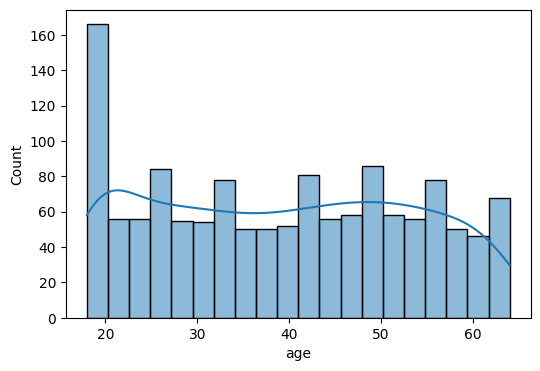

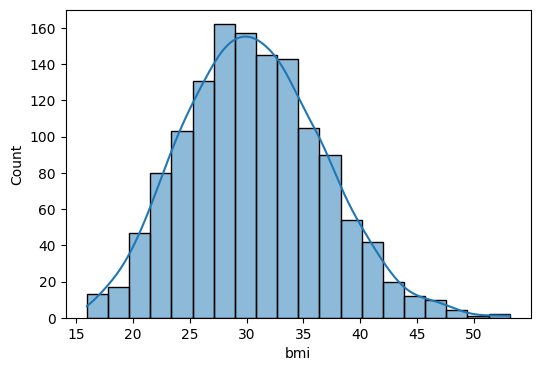

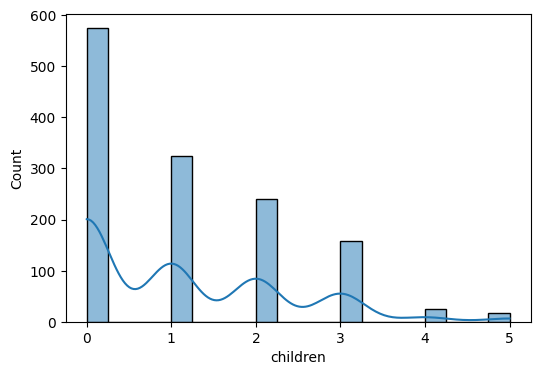

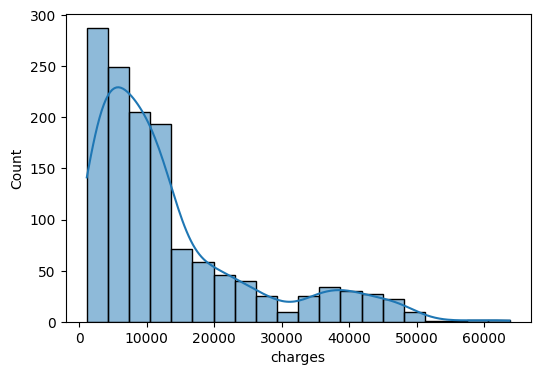

In [99]:
for i in num_col:
  plt.figure(figsize=(6,4))
  sns.histplot(df[i] , kde = True , bins = 20)

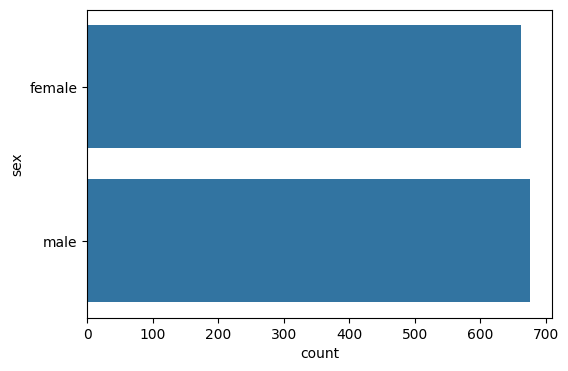

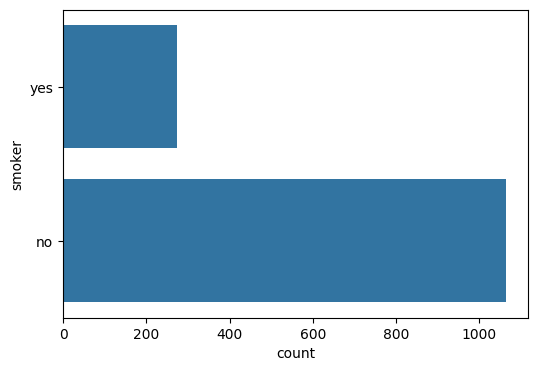

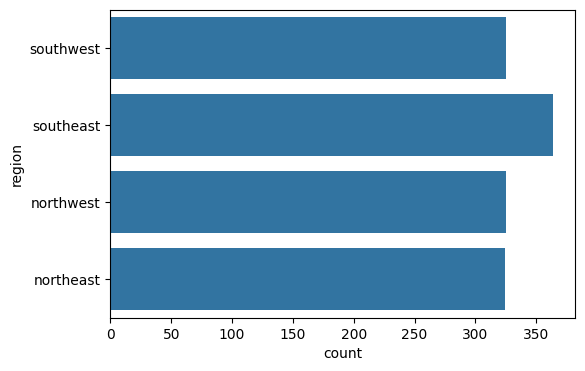

In [100]:
for i in cat_col:
  plt.figure(figsize = (6,4))
  sns.countplot(df[i])

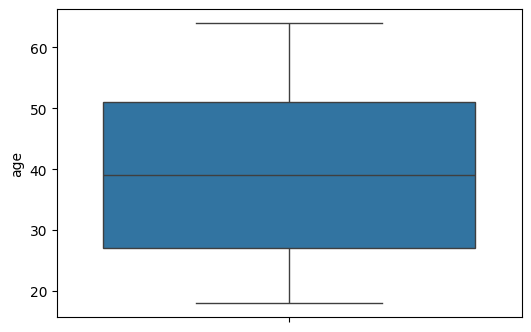

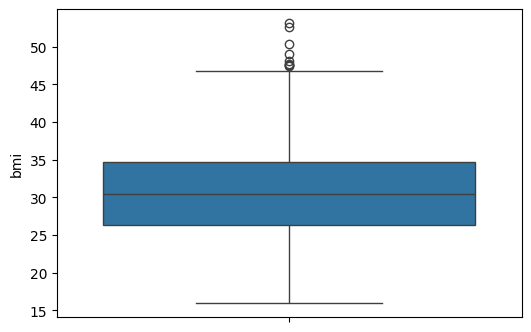

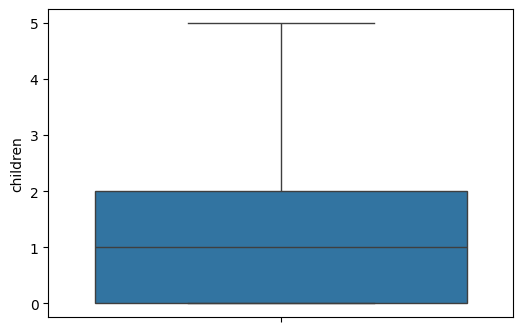

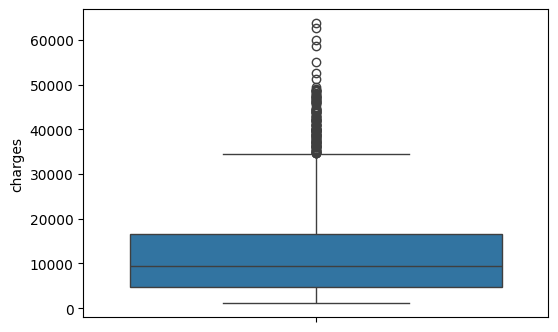

In [101]:
for i in num_col:
  plt.figure(figsize=(6,4))
  sns.boxplot(df[i])

<Axes: >

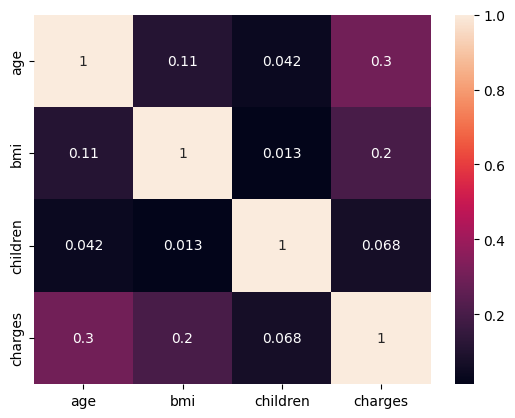

In [102]:
sns.heatmap(df.corr(numeric_only= True) , annot = True)

In [103]:
# Data Cleaning and preprocessing

In [104]:
df.isnull().sum()

,0
age,0
sex,0
bmi,0
children,0
smoker,0
region,0
charges,0


In [105]:
df.dropna()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.54830
1334,18,female,31.920,0,no,northeast,2205.98080
1335,18,female,36.850,0,no,southeast,1629.83350
1336,21,female,25.800,0,no,southwest,2007.94500


In [106]:
df.drop_duplicates(inplace  =True)

In [107]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [108]:
df['sex'] = df['sex'].map({
    'male' : 0 ,
    'female' : 1
})

In [109]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,1,27.900,0,yes,southwest,16884.92400
1,18,0,33.770,1,no,southeast,1725.55230
2,28,0,33.000,3,no,southeast,4449.46200
3,33,0,22.705,0,no,northwest,21984.47061
4,32,0,28.880,0,no,northwest,3866.85520


In [110]:
df['smoker'].value_counts()

,count
smoker,
no,1063
yes,274


In [111]:
df['smoker'] = df['smoker'].map(
    { 'yes' : 0,
     'no' : 1
})

In [112]:
df = pd.get_dummies(df, columns=['region'], drop_first=True)

In [113]:
df.head()

,age,sex,bmi,children,smoker,charges,region_northwest,region_southeast,region_southwest
0,19,1,27.900,0,0,16884.92400,False,False,True
1,18,0,33.770,1,1,1725.55230,False,True,False
2,28,0,33.000,3,1,4449.46200,False,True,False
3,33,0,22.705,0,1,21984.47061,True,False,False
4,32,0,28.880,0,1,3866.85520,True,False,False


In [114]:
df['region_northwest'] = df['region_northwest'].astype(int)
df['region_southeast'] = df['region_southeast'].astype(int)
df['region_southwest'] = df['region_southwest'].astype(int)

In [115]:
df.head()

,age,sex,bmi,children,smoker,charges,region_northwest,region_southeast,region_southwest
0,19,1,27.900,0,0,16884.92400,0,0,1
1,18,0,33.770,1,1,1725.55230,0,1,0
2,28,0,33.000,3,1,4449.46200,0,1,0
3,33,0,22.705,0,1,21984.47061,1,0,0
4,32,0,28.880,0,1,3866.85520,1,0,0


<Axes: xlabel='bmi', ylabel='Count'>

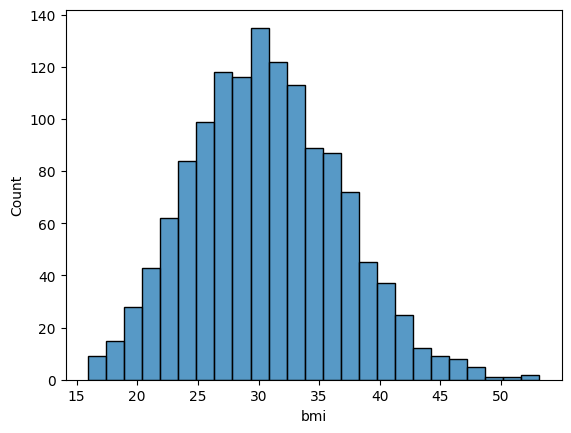

In [116]:
sns.histplot(df['bmi'])

In [117]:
df['bmi_category'] = pd.cut(df['bmi'] , bins = [0 , 18.5 , 24.9 , 29.9 , float('inf')], labels = ['Underweight' , 'Normal' , 'Overweight' , 'Obese'])

In [118]:
df.head()

,age,sex,bmi,children,smoker,charges,region_northwest,region_southeast,region_southwest,bmi_category
0,19,1,27.900,0,0,16884.92400,0,0,1,Overweight
1,18,0,33.770,1,1,1725.55230,0,1,0,Obese
2,28,0,33.000,3,1,4449.46200,0,1,0,Obese
3,33,0,22.705,0,1,21984.47061,1,0,0,Normal
4,32,0,28.880,0,1,3866.85520,1,0,0,Overweight


In [119]:
df = pd.get_dummies(df, columns=['bmi_category'] , drop_first = True)
df = df.astype(int)

In [120]:
df.head()

,age,sex,bmi,children,smoker,charges,region_northwest,region_southeast,region_southwest,bmi_category_Normal,bmi_category_Overweight,bmi_category_Obese
0,19,1,27,0,0,16884,0,0,1,0,1,0
1,18,0,33,1,1,1725,0,1,0,0,0,1
2,28,0,33,3,1,4449,0,1,0,0,0,1
3,33,0,22,0,1,21984,1,0,0,1,0,0
4,32,0,28,0,1,3866,1,0,0,0,1,0


In [121]:
df.rename(
    columns = {
        'sex' : 'Gender'
    }
)

,age,Gender,bmi,children,smoker,charges,region_northwest,region_southeast,region_southwest,bmi_category_Normal,bmi_category_Overweight,bmi_category_Obese
0,19,1,27,0,0,16884,0,0,1,0,1,0
1,18,0,33,1,1,1725,0,1,0,0,0,1
2,28,0,33,3,1,4449,0,1,0,0,0,1
3,33,0,22,0,1,21984,1,0,0,1,0,0
4,32,0,28,0,1,3866,1,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...
1333,50,0,30,3,1,10600,1,0,0,0,0,1
1334,18,1,31,0,1,2205,0,0,0,0,0,1
1335,18,1,36,0,1,1629,0,1,0,0,0,1
1336,21,1,25,0,1,2007,0,0,1,0,1,0


In [123]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
col = ['age' , 'children' , 'bmi']
df[col]  = scaler.fit_transform(df[col])


In [124]:
df.head()

,age,sex,bmi,children,smoker,charges,region_northwest,region_southeast,region_southwest,bmi_category_Normal,bmi_category_Overweight,bmi_category_Obese
0,-1.440418,1,-0.517949,-0.909234,0,16884,0,0,1,0,1,0
1,-1.511647,0,0.462463,-0.079442,1,1725,0,1,0,0,0,1
2,-0.799350,0,0.462463,1.580143,1,4449,0,1,0,0,0,1
3,-0.443201,0,-1.334960,-0.909234,1,21984,1,0,0,1,0,0
4,-0.514431,0,-0.354547,-0.909234,1,3866,1,0,0,0,1,0


In [128]:
from scipy.stats import pearsonr

# ----------------------------------
# Pearson Correlation Calculation
# ----------------------------------

# List of features to check against target
selected_features = [
    'age', 'bmi', 'children', 'sex', 'smoker',
    'region_northwest', 'region_southeast', 'region_southwest',
    'bmi_category_Normal', 'bmi_category_Overweight', 'bmi_category_Obese'
]

correlations = {
    feature: pearsonr(df[feature], df['charges'])[0]
    for feature in selected_features
}
correlation_df = pd.DataFrame(list(correlations.items()), columns=['Feature', 'Pearson Correlation'])
correlation_df.sort_values(by='Pearson Correlation', ascending=False)

,Feature,Pearson Correlation
0,age,0.298309
10,bmi_category_Obese,0.197660
1,bmi,0.196236
6,region_southeast,0.073577
2,children,0.067390
5,region_northwest,-0.038695
7,region_southwest,-0.043637
3,sex,-0.058046
8,bmi_category_Normal,-0.105656
9,bmi_category_Overweight,-0.118280


In [129]:
cat_features = [
    'sex', 'smoker',
    'region_northwest', 'region_southeast', 'region_southwest',
    'bmi_category_Normal', 'bmi_category_Overweight', 'bmi_category_Obese'
]

In [130]:
from scipy.stats import chi2_contingency
import pandas as pd

alpha = 0.05

df['charges_bin'] = pd.qcut(df['charges'], q=4, labels=False)
chi2_results = {}

for col in cat_features:
    contingency = pd.crosstab(df[col], df['charges_bin'])
    chi2_stat, p_val, _, _ = chi2_contingency(contingency)
    decision = 'Reject Null (Keep Feature)' if p_val < alpha else 'Accept Null (Drop Feature)'
    chi2_results[col] = {
        'chi2_statistic': chi2_stat,
        'p_value': p_val,
        'Decision': decision
    }

chi2_df = pd.DataFrame(chi2_results).T
chi2_df = chi2_df.sort_values(by='p_value')
chi2_df

,chi2_statistic,p_value,Decision
smoker,848.219178,0.0,Reject Null (Keep Feature)
region_southeast,15.998167,0.001135,Reject Null (Keep Feature)
sex,10.258784,0.01649,Reject Null (Keep Feature)
bmi_category_Obese,7.654464,0.05372,Accept Null (Drop Feature)
region_southwest,5.091893,0.165191,Accept Null (Drop Feature)
bmi_category_Normal,4.263673,0.234364,Accept Null (Drop Feature)
bmi_category_Overweight,4.201575,0.240504,Accept Null (Drop Feature)
region_northwest,1.13424,0.768815,Accept Null (Drop Feature)


In [133]:
final_df = df[['age', 'sex', 'bmi', 'children', 'smoker', 'charges','region_southeast','bmi_category_Obese']]

In [134]:
final_df

,age,sex,bmi,children,smoker,charges,region_southeast,bmi_category_Obese
0,-1.440418,1,-0.517949,-0.909234,0,16884,0,0
1,-1.511647,0,0.462463,-0.079442,1,1725,1,1
2,-0.799350,0,0.462463,1.580143,1,4449,1,1
3,-0.443201,0,-1.334960,-0.909234,1,21984,0,0
4,-0.514431,0,-0.354547,-0.909234,1,3866,0,0
...,...,...,...,...,...,...,...,...
1333,0.767704,0,-0.027743,1.580143,1,10600,0,1
1334,-1.511647,1,0.135659,-0.909234,1,2205,0,1
1335,-1.511647,1,0.952670,-0.909234,1,1629,1,1
1336,-1.297958,1,-0.844753,-0.909234,1,2007,0,0


In [135]:
df = final_df.copy()

In [136]:
df

,age,sex,bmi,children,smoker,charges,region_southeast,bmi_category_Obese
0,-1.440418,1,-0.517949,-0.909234,0,16884,0,0
1,-1.511647,0,0.462463,-0.079442,1,1725,1,1
2,-0.799350,0,0.462463,1.580143,1,4449,1,1
3,-0.443201,0,-1.334960,-0.909234,1,21984,0,0
4,-0.514431,0,-0.354547,-0.909234,1,3866,0,0
...,...,...,...,...,...,...,...,...
1333,0.767704,0,-0.027743,1.580143,1,10600,0,1
1334,-1.511647,1,0.135659,-0.909234,1,2205,0,1
1335,-1.511647,1,0.952670,-0.909234,1,1629,1,1
1336,-1.297958,1,-0.844753,-0.909234,1,2007,0,0
